# 05 DoubleSersicModel Workflow

This notebook validates the user-facing `DoubleSersicModel` API.

The goal is to show that `DoubleSersicModel` is a lightweight scientific wrapper around the more general `CompositeModel`, while remaining fully compatible with:

- `ConvolvedModel`
- `ParameterSet`
- `DynestyFitter`
- posterior summaries
- logarithmic image visualization
- residual analysis


## 1. Imports

In [1]:
import numpy as np

from baymorph import (
    ConvolvedModel,
    DoubleSersicModel,
    DynestyFitter,
    GaussianPSF,
    Parameter,
    ParameterSet,
    SersicModel,
    add_gaussian_noise,
    make_constant_noise_map,
    plot_log_data_model_residual,
    show_log_image,
)

## 2. True bulge and disk parameters

In [2]:
true_flux_bulge = 3000.0
true_re_bulge = 6.0
true_n_bulge = 4.0

true_flux_disk = 7000.0
true_re_disk = 12.0
true_n_disk = 1.0

true_q = 0.8
true_theta = 0.0
true_x0 = 30.0
true_y0 = 30.0

## 3. Build the true DoubleSersicModel

In [3]:
true_bulge = SersicModel(
    flux=true_flux_bulge,
    re=true_re_bulge,
    n=true_n_bulge,
    q=true_q,
    theta=true_theta,
    x0=true_x0,
    y0=true_y0,
)

true_disk = SersicModel(
    flux=true_flux_disk,
    re=true_re_disk,
    n=true_n_disk,
    q=true_q,
    theta=true_theta,
    x0=true_x0,
    y0=true_y0,
)

true_model = DoubleSersicModel(
    bulge=true_bulge,
    disk=true_disk,
)

## 4. Apply PSF convolution

In [4]:
psf = GaussianPSF(
    fwhm=3.0,
)

true_model_psf = ConvolvedModel(
    true_model,
    psf,
)

## 5. Generate a noisy mock observation

In [5]:
clean_image = true_model_psf.render(
    shape=(60, 60),
)

data = add_gaussian_noise(
    clean_image,
    sigma=1.0,
    seed=42,
)

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

## 6. Display the mock galaxy

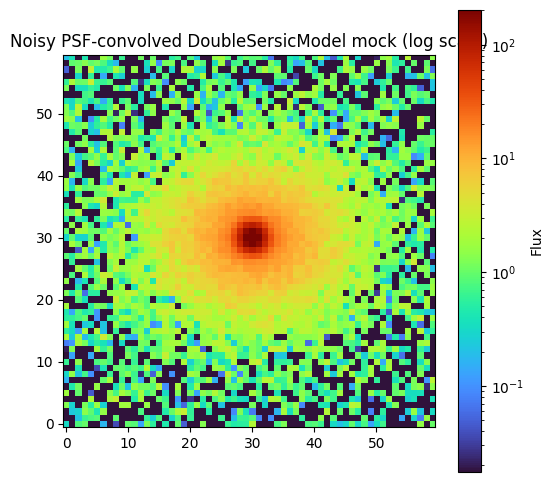

In [6]:
show_log_image(
    data,
    title="Noisy PSF-convolved DoubleSersicModel mock",
)

## 7. Define the fitting model factory

In [7]:
def model_factory(
    flux_bulge,
    re_bulge,
    flux_disk,
    re_disk,
):
    bulge = SersicModel(
        flux=flux_bulge,
        re=re_bulge,
        n=true_n_bulge,
        q=true_q,
        theta=true_theta,
        x0=true_x0,
        y0=true_y0,
    )

    disk = SersicModel(
        flux=flux_disk,
        re=re_disk,
        n=true_n_disk,
        q=true_q,
        theta=true_theta,
        x0=true_x0,
        y0=true_y0,
    )

    double_sersic = DoubleSersicModel(
        bulge=bulge,
        disk=disk,
    )

    return ConvolvedModel(
        double_sersic,
        psf,
    )

## 8. Define fitted parameters

In [8]:
parameters = ParameterSet(
    [
        Parameter(
            "flux_bulge",
            500.0,
            6000.0,
        ),
        Parameter(
            "re_bulge",
            1.0,
            8.0,
        ),
        Parameter(
            "flux_disk",
            3000.0,
            12000.0,
        ),
        Parameter(
            "re_disk",
            5.0,
            20.0,
        ),
    ]
)

## 9. Build the fitter

In [9]:
fitter = DynestyFitter(
    model_factory=model_factory,
    data=data,
    noise=noise,
    parameters=parameters,
)

## 10. Run Dynesty

In [10]:
result = fitter.run(
    nlive=150,
    sample="rwalk",
    print_progress=True,
)

iter: 2644 | +150 | bound: 15 | nc: 1 | ncall: 56132 | eff(%):  4.991 | loglstar:   -inf < -5108.009 <    inf | logz: -5123.693 +/-  0.308 | dlogz:  0.001 >  0.159                                   

## 11. Best-fit parameters

In [11]:
result.best_parameters

{'flux_bulge': 2972.7632833463626,
 're_bulge': 5.796152362074448,
 'flux_disk': 6993.088314944887,
 're_disk': 12.050450434714003}

## 12. Posterior summaries

In [12]:
for parameter in [
    "flux_bulge",
    "re_bulge",
    "flux_disk",
    "re_disk",
]:
    print(parameter)
    print(
        result.summary(parameter)
    )
    print()

flux_bulge
{'q16': 2874.108604504555, 'median': 2969.4615133333828, 'q84': 3061.1255960449}

re_bulge
{'q16': 5.209571259871363, 'median': 5.769557296623277, 'q84': 6.293825452888458}

flux_disk
{'q16': 6888.526210150344, 'median': 6986.791930043719, 'q84': 7071.840319706616}

re_disk
{'q16': 11.900346518911874, 'median': 12.022142586244652, 'q84': 12.15209365369923}



## 13. Render the best-fit model

In [13]:
best = result.best_parameters

best_model = model_factory(
    flux_bulge=best["flux_bulge"],
    re_bulge=best["re_bulge"],
    flux_disk=best["flux_disk"],
    re_disk=best["re_disk"],
)

best_image = best_model.render(
    shape=data.shape,
)

## 14. Data, model, and residuals

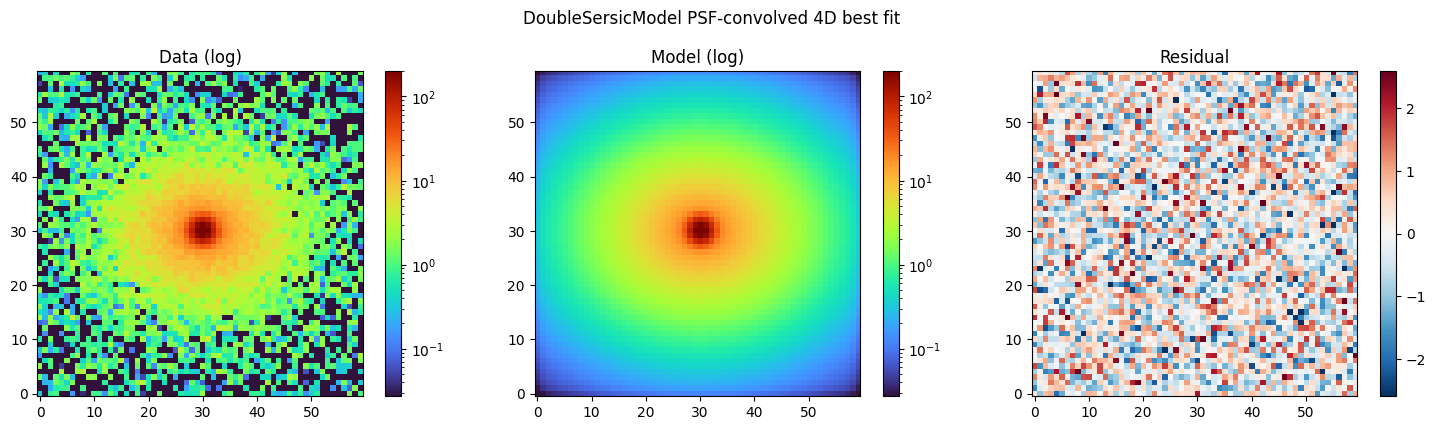

In [14]:
plot_log_data_model_residual(
    data,
    best_image,
    title="DoubleSersicModel PSF-convolved 4D best fit",
)

## 15. Quantitative recovery

In [15]:
truth = {
    "flux_bulge": true_flux_bulge,
    "re_bulge": true_re_bulge,
    "flux_disk": true_flux_disk,
    "re_disk": true_re_disk,
}

for name, true_value in truth.items():
    recovered_value = best[name]

    error_percent = 100.0 * (
        recovered_value - true_value
    ) / true_value

    print(name)
    print("  true:", true_value)
    print("  recovered:", recovered_value)
    print("  error (%):", error_percent)
    print()

flux_bulge
  true: 3000.0
  recovered: 2972.7632833463626
  error (%): -0.9078905551212453

re_bulge
  true: 6.0
  recovered: 5.796152362074448
  error (%): -3.397460632092534

flux_disk
  true: 7000.0
  recovered: 6993.088314944887
  error (%): -0.09873835793018121

re_disk
  true: 12.0
  recovered: 12.050450434714003
  error (%): 0.42042028928335934



## 16. Conclusion

This notebook validates `DoubleSersicModel` as the user-facing bulge+disk API.

The workflow demonstrates that:

```text
DoubleSersicModel
    ↓
ConvolvedModel
    ↓
ParameterSet
    ↓
DynestyFitter
    ↓
PosteriorResult
```

works without modifying the fitting backend.


When the bulge effective radius is comparable to the PSF FWHM, re_bulge is less tightly recovered.
Increasing the intrinsic bulge size improves the recovery, confirming that the limitation is resolution-driven rather than architectural.